## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Helen Ayalew

**Date:** 10/09/2026

In [487]:
# Your Phase 1 solution to the problem goes here.

# All imports needed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

In [488]:
# Displaying the contents from this dataframe
df0_125

,x1,x2,group
0,0.781279,0.851498,a
1,1.042835,0.931282,a
2,1.144129,0.882494,a
3,0.968445,0.896508,a
4,1.122665,1.013608,a
...,...,...,...
45,5.144996,2.890534,c
46,5.087773,3.014701,c
47,4.839512,2.880229,c
48,5.190288,2.764861,c


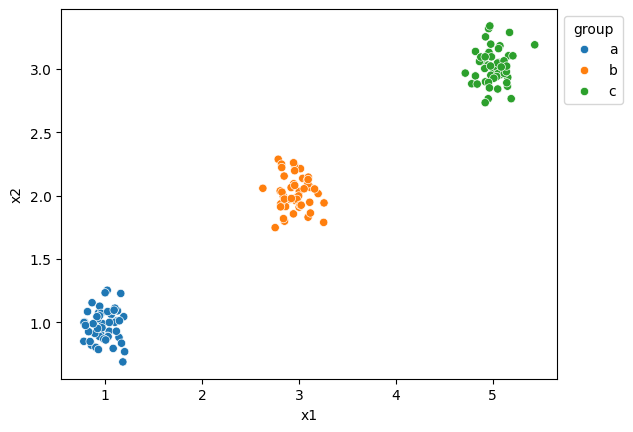

In [489]:
# Make scatterplots of the (X1, X2) points by group for each of the datasets.

# scatterplot for 0.125 dataframe
ax = sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

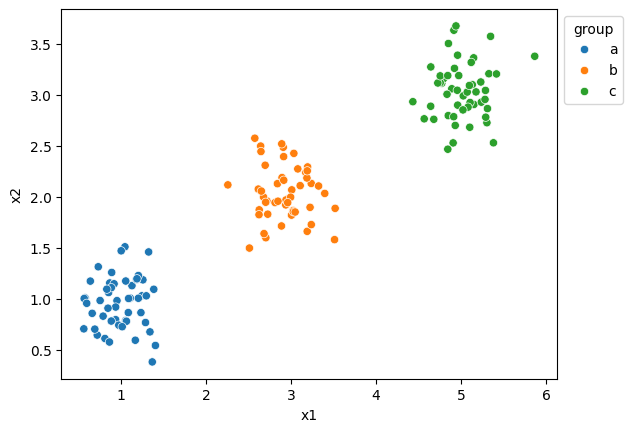

In [490]:
# scatterplot for 0.25 dataframe
ax = sns.scatterplot(data=df0_25, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

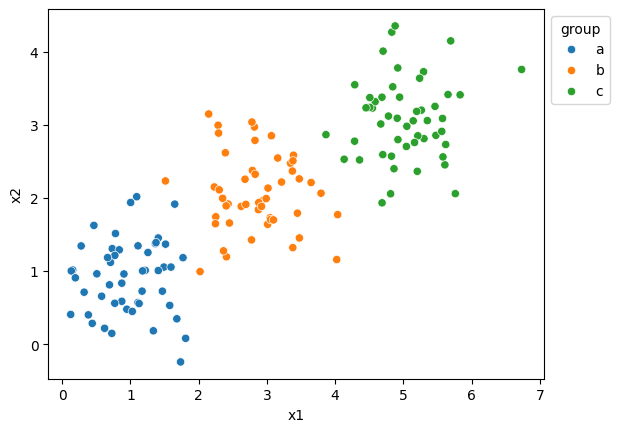

In [491]:
# scatterplot for 0.5 dataframe
ax = sns.scatterplot(data=df0_5, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

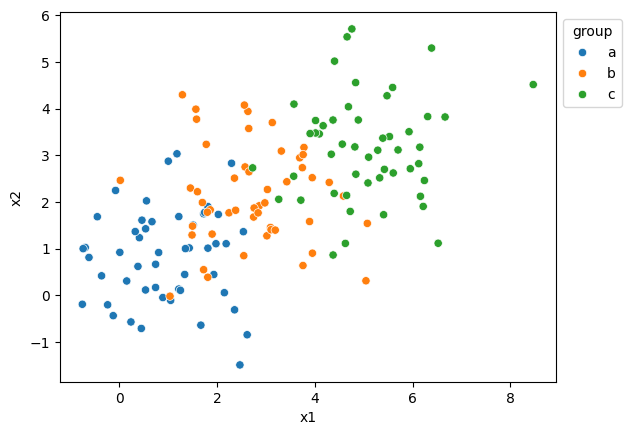

In [492]:
# scatterplot for 1.0 dataframe
ax = sns.scatterplot(data=df1_0, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

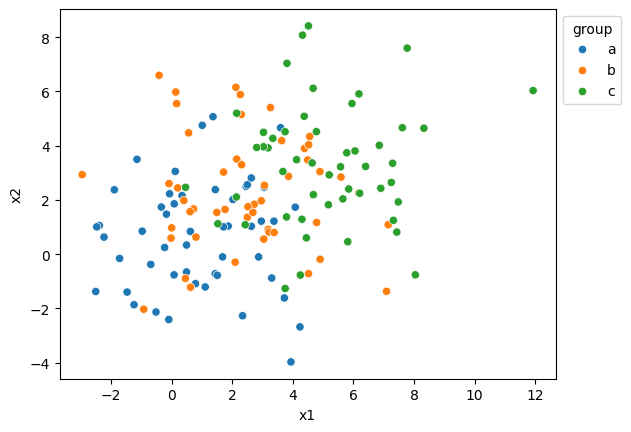

In [493]:
# scatterplot for 2.0 dataframe
ax = sns.scatterplot(data=df2_0, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

Question: As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

Answer: As the `noise` goes up from 0.125 to 2.0, the visual distinctness of the clusters get closer and closer together. The clustered points are overlapping one another as the `noise` goes up, closer to the origin.

[Text(0.5, 1.0, 'Scree Plot for 0.125'),
 Text(0.5, 0, 'k'),
 Text(0, 0.5, 'SSE')]

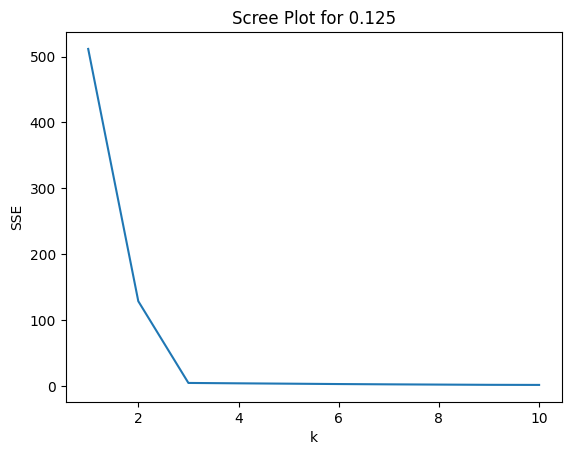

In [494]:
# Create a scree plot for each of the datasets

# Scree plot for 0.125 dataframe
X = df0_125[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 0.125", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 0.25'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

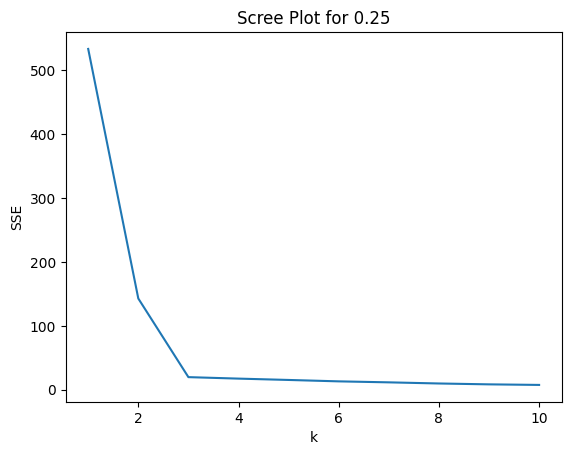

In [495]:
# Scree plot for 0.25 dataframe
X = df0_25[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 0.25", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 0.5'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

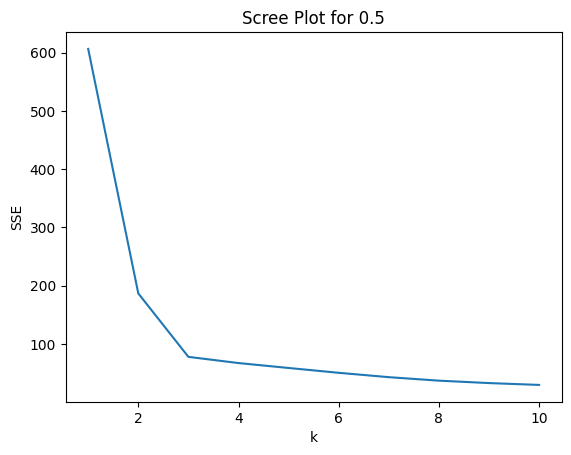

In [496]:
# Scree plot for 0.5 dataframe
X = df0_5[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 0.5", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 1.0'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

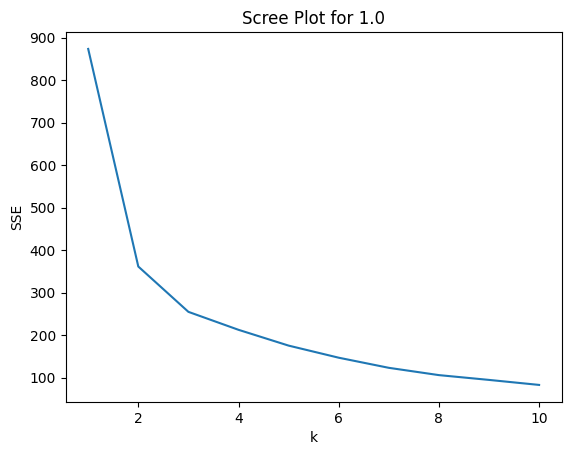

In [497]:
# Scree plot for 1.0 dataframe
X = df1_0[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 1.0", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 2.0'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

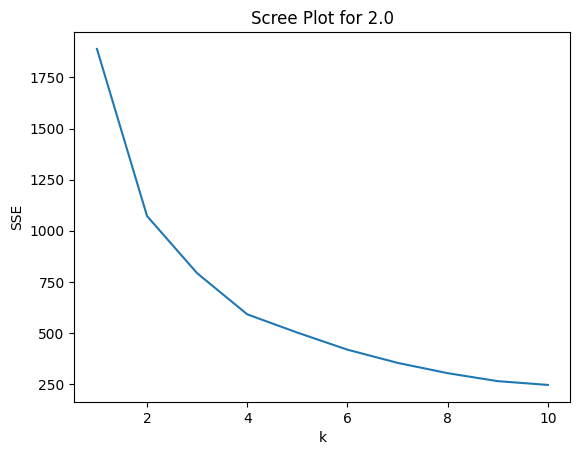

In [498]:
# Scree plot for 2.0 dataframe
X = df2_0[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 2.0", xlabel="k", ylabel="SSE")

Question: Describe how the level of noise affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

Answer: The level of noise affects the scree plots especially the elbow where the true k value is shown. The noise and SSE increase and decrease at the same rate. As noise increases, the rate of SSE also increases. The k value that would work for all of them would be when k is 3.

Question: Explain the intuition of the elbow, using this numerical simulation as an example.

Answer: Elbow is used to help determine the best k value which is the optimal number of clusters. As seen in the scree plots for each variation of noise, the number of clusters (k values) are consistantly 3 because it is where the graph curves. When the noise was 0.125, the graph had a sharper curve and the SSE values is up to 500 whereas when the noise was 2.0, the graph had looser curve and the SSE values when up to 1750.

In [499]:
# All of my imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Loaded the `SIPRI Military Expenditure Database.csv` from the `./data` folder.
# Saving the csv data to a pandas dataframe
df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
df.head()

# Copy of cleaned SIPRI Military Expenditure Database from originial data set
df.to_csv('/content/SIPRI Military Expenditure Database.csv', index=False)

# Checking the dataframe contents
df

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
5877,5877,2017,Zimbabwe,571.920778,0.003878,1.385588,23.918101
5878,5878,2018,Zimbabwe,638.310913,0.003093,1.401774,29.113096
5879,5879,2019,Zimbabwe,796.573534,0.005348,1.761478,37.346466
5880,5880,2020,Zimbabwe,8.622460,0.000054,0.018941,0.580129


In [500]:
# Filtered the rows to select only the year 2020
df = df[df['Year'] == 2020]

# Drop all rows with missing values
df = df.dropna()

# Displaying these changes
df

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


In [501]:
# Displaying these to determine whether there is further cleaning required
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


Question: I ended up with 148 countries. Is any further cleaning of the variables required?

Answer: Yes, the indexes for each entry in the dataframe must be fixed so that it matches the physical location of where it is stored in the updated dataframe. It will make it easier understandable and accessible now that the data has been cleaned.

[Text(0.5, 1.0, 'Scree Plot for Spending (2020 USD) and Per Capita'),
 Text(0.5, 0, 'k'),
 Text(0, 0.5, 'SSE')]

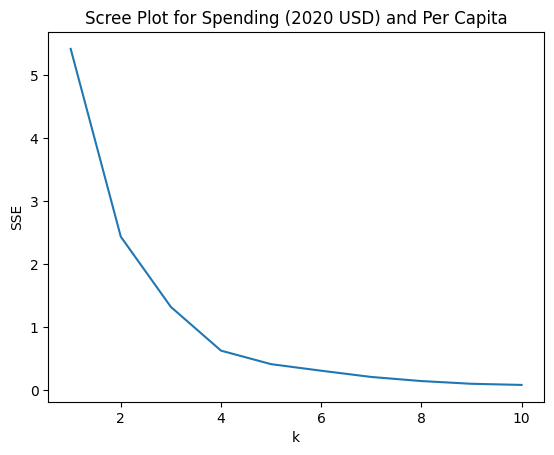

In [502]:
# Max-min normalize Spending (2020 USD) and Spending per Capita.
df['Spending'] = (df['Spending (2020 USD)'] - df['Spending (2020 USD)'].min()) / (df['Spending (2020 USD)'].max() - df['Spending (2020 USD)'].min())
df['Per Capita'] = (df['Spending per Capita'] - df['Spending per Capita'].min()) / (df['Spending per Capita'].max() - df['Spending per Capita'].min())

# Use a scree plot to determine the optimal number of clusters for the  k  means clustering algorithm.
# Scree plot for Spending (2020 USD) and Spending per Capita
X = df[['Spending', 'Per Capita']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for Spending (2020 USD) and Per Capita", xlabel="k", ylabel="SSE")

index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0        126.0  2795.984127  1652.593453    32.0  1332.5  2769.0  4205.5   
1          4.0  3661.500000  1061.604289  2582.0  2837.0  3704.0  4528.5   
2          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   
3         17.0  2738.000000  1716.329077   236.0  1426.0  2854.0  4010.0   

                  Year          ...  Spending           Per Capita            \
            max  count    mean  ...       75%       max      count      mean   
cluster                         ...                                            
0        5880.0  126.0  2020.0  ...  0.004133  0.331409      126.0  0.048200   
1        4656.0    4.0  2020.0  ...  0.041744  0.082927        4.0  0.764277   
2        5540.0    1.0  2020.0  ...  1.000000  1.000000        1.0  0.933024   
3        5506.0   17.0  2020.0  ...  0.035063  0.077938       17.0  0.332880   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.055576  0.000000  0.007114  0.023108  0.074477  0.214529  
1        0.161603  0.644720  0.668704  0.706194  0.801766  1.000000  
2             NaN  0.933024  0.933024  0.933024  0.933024  0.933024  
3        0.083535  0.244571  0.257021  0.320462  0.354469  0.531974  

[4 rows x 64 columns]

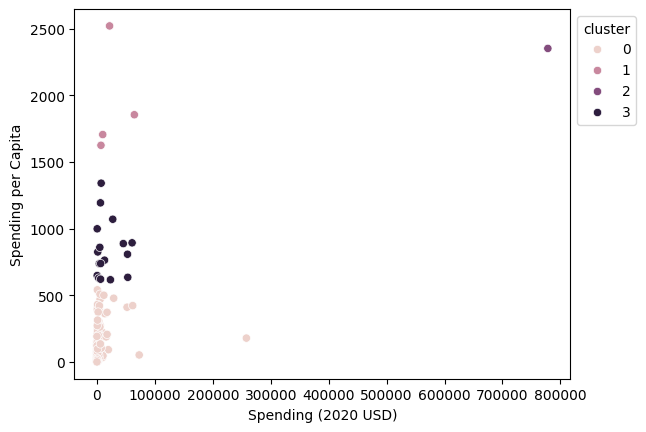

In [503]:
# Make a scatter plot of Spending (2020 USD) and Spending per Capita, and hue the dots by their cluster membership.
hierarchical = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X)
df["cluster"] = hierarchical.labels_
ax = sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

# Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()).
df.groupby('cluster').describe()

Question: What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

Answer: I see most of the USD spent in 2020 mostly towards the left near the origin and as the number of clusters increase, the cluster groups increase upwards. The United States is in the clusters higher up in the graph. The patterns that I have noticed in the cluster memberships is that the smaller clusters (such as cluster = 0) is closer together near the origin whereas the clusters (such as cluster = 2) is on its own in the top right.

[Text(0.5, 1.0, 'Scree Plot for Percent of Government Spending and GDP'),
 Text(0.5, 0, 'k'),
 Text(0, 0.5, 'SSE')]

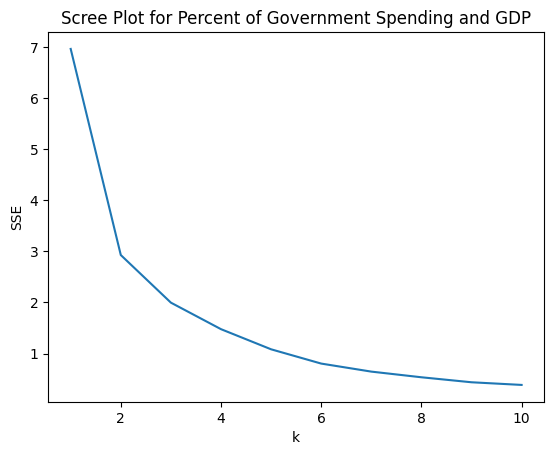

In [504]:
# Max-min normalize Percent of Government Spending and Percent of GDP.
df['Government'] = (df['Percent of Government Spending'] - df['Percent of Government Spending'].min()) / (df['Percent of Government Spending'].max() - df['Percent of Government Spending'].min())
df['GDP'] = (df['Percent of GDP'] - df['Percent of GDP'].min()) / (df['Percent of GDP'].max() - df['Percent of GDP'].min())

# Use a scree plot to determine the optimal number of clusters for the  k  means clustering algorithm.
# Scree plot for Percent of Government Spending and Percent of GDP
X = df[['Government', 'GDP']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for Percent of Government Spending and GDP", xlabel="k", ylabel="SSE")

index                                                            \
        count         mean          std     min     25%     50%     75%   
cluster                                                                   
0        33.0  2633.515152  1787.712297   100.0   814.0  2718.0  3738.0   
1        85.0  2851.600000  1567.566534    32.0  1596.0  2888.0  4146.0   
2         2.0  4265.000000   312.541197  4044.0  4154.5  4265.0  4375.5   
3        28.0  2900.142857  1804.818401   134.0  1477.0  2616.0  4622.0   

                 Year          ... Government             GDP            \
            max count    mean  ...        75%       max count      mean   
cluster                        ...                                        
0        5540.0  33.0  2020.0  ...   0.423599  1.000000  33.0  0.365696   
1        5880.0  85.0  2020.0  ...   0.121370  0.193838  85.0  0.113854   
2        4486.0   2.0  2020.0  ...   0.701219  0.738448   2.0  0.968198   
3        5574.0  28.0  2020.0  ...   0.246493  0.324036  28.0  0.204985   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.121645  0.118758  0.292556  0.331220  0.414106  0.676168  
1        0.047704  0.000000  0.075707  0.112637  0.146529  0.203631  
2        0.044974  0.936397  0.952298  0.968198  0.984099  1.000000  
3        0.041062  0.114445  0.186722  0.206956  0.229681  0.285294  

[4 rows x 80 columns]

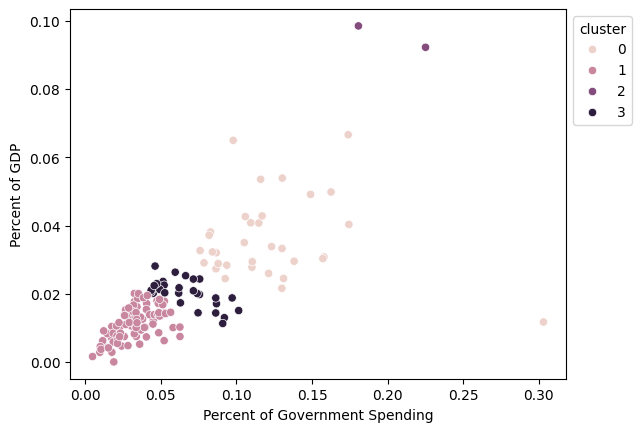

In [505]:
# Make a scatter plot of Percent of Government Spending and Percent of GDP, and hue the dots by their cluster membership.
hierarchical = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X)
df["cluster"] = hierarchical.labels_
ax = sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

# Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()).
df.groupby('cluster').describe()

Question: How do your results compare to part 2?

Answer: The results in the scree plot from part 1 (Spending (2020 USD) and Spending per Capita) to part 2 (Percent of Government Spending and Percent of GDP) SSE grew from 5 to 7 and the steepness of the slope of the curve isn't as sharp. The results in the scatter plots from part 1 to part 2 has changed. The overall pattern has changed from the clusters being in one general area growing up to a gradual slope with clusters starting near the origin to the top right.

[Text(0.5, 1.0, 'Scree Plot for All Four Numeric Variables'),
 Text(0.5, 0, 'k'),
 Text(0, 0.5, 'SSE')]

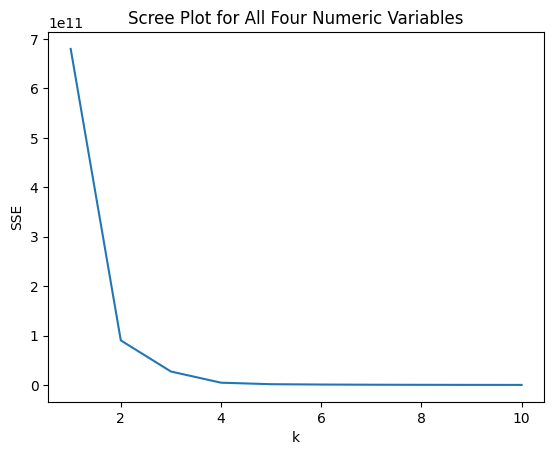

In [506]:
# Use k means clustering with all four numeric variables: Spending (2020 USD), Spending per Capita, Percent of Government Spending, and Percent of GDP.
X = df[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for All Four Numeric Variables", xlabel="k", ylabel="SSE")

Question: How do your results compare to the previous two parts?

Answer: This scree plot compared to the previous two parts is much steeper and sharper slope with a defined k value as well as SSE values reaching 7 similar to part 2. I did notice that this graph is closer to the x-axis where the k values are because the values start to flatten near when k is 3.

Question: Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

Answer: The $k$-MC algorithm did not find useful patterns for analyzing and comparing the spending because the clusters were very close. It gave me an idea of how much they were spending in 2020 based from the data and the graphical visuals.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** bc6a9279ac270217bd6b3de4acfe427e32171a78
- **AI tool and model used:** Google Gemini

### *Prompts used

1. Would you be able to give me an critics on my program based on these problems and my solution?

    **Pasted the all parts of Question 1**

    My solution:

    **Placed my code here**

2. Can you give me an critics on my program based on the problems and my soluion?

    **Pasted the all parts of Question 2**

    My solution:

    **Placed my code here**

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Question 1 Feedback

    Code Structure and Best Practices
    
    - Strengths: Your script successfully implements the data generation function, computes the KMeans inertia across different values of $k$, and uses Seaborn effectively for plotting. Setting random_state is also a great practice for reproducibility.

    - Areas for Improvement:
      - Code Redundancy: You repeat the KMeans loop five times. You can condense this significantly by looping through a dictionary or list of your dataframes.
      - Addressing the Instructions: The instructions specifically noted: (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.) Your current code generates separate plots, making it harder to visually compare how drastically the scale of the vertical axis (SSE) changes as noise increases.
  
2. Question 2 Feedback

    Critique of Written Answer 1: Scree Plots & Noise
    
    Your Answer: The level of noise affects the scree plots especially the elbow where the true k value is shown. The noise and SSE increase and decrease at the same rate. As noise increases, the rate of SSE also increases. The k value that would work for all of them would be when k is 3.
    
    - Critique:
      - Saying "noise and SSE increase and decrease at the same rate" is a bit inaccurate. Instead, state that as noise increases, the overall SSE shifts upward because the data points are more dispersed from their cluster centers.
      - More importantly, you missed describing how the elbow changes: with low noise ($0.125$), there is a very sharp, distinct bend (elbow) at $k=3$. As noise increases to $2.0$, that bend smooths out significantly, making it much harder to definitively select $k=3$ from the scree plot alone.
  
3. Question 3 Feedback
    Critique of Written Answer 2: Elbow Intuition
    
    Your Answer: Elbow is used to help determine the best k value which is the optimal number of clusters... When the noise was 0.125, the graph had a sharper curve and the SSE values is up to 500 whereas when the noise was 2.0, the graph had looser curve and the SSE values when up to 1750.
    
    - Critique:
      - You correctly observed the shift in SSE values (500 up to 1750) and the sharpness of the curve.
      - However, the prompt asks you to explain the intuition of the elbow using this simulation. The core intuition is that up to $k=3$, each added cluster corresponds to one of the true underlying groups you generated ($X_1, X_2, X_3$), leading to a massive drop in error. Once $k$ exceeds 3, adding more clusters merely starts slicing up the random noise within those three groups, yielding diminishing returns and causing the slope to flatten out into the "arm" of the elbow.

4. Question 4 Feedback
    Suggested Refined Answers for Submission
    
    If you want to polish your final write-up, consider framing your answers like this:
    
    - On the effect of noise: As the noise parameter increases from $0.125$ to $2.0$, the overall Sum of Squared Errors (SSE) increases dramatically across all values of $k$ (scaling up from ~500 to ~1750). Visually, low-noise datasets exhibit a sharp, unmistakable bend at $k=3$. As noise increases, the curves become much smoother and more gradual, destroying the distinct "elbow" and making it increasingly difficult to definitively identify the true number of clusters ($k=3$) without prior knowledge.
    - On the intuition of the elbow: The elbow represents the point of diminishing returns. In this simulation, we generated data around 3 distinct centers. Up to $k=3$, increasing the number of clusters successfully captures these distinct underlying groups, causing a steep drop in SSE. Beyond $k=3$, additional clusters no longer capture separate groups; instead, they arbitrarily split up the random noise within the three clusters, resulting in a much flatter, linear decrease in error.

5. Question 5 Feedback
    Code Structure and Technical Critique
    
    1. Mismatch Between Instructions and Implementation ($K$-Means vs. Hierarchical)
      - The Issue: The instructions explicitly ask you to "determine the optimal number of clusters for the $k$ means clustering algorithm" and use $k$-means clustering. However, in your code, you use AgglomerativeClustering(n_clusters=4, linkage="ward") to assign the cluster labels for your scatter plots.
      - The Fix: Switch your cluster assignment step to use KMeans to stay consistent with the instructions and the scree plots you generated:

        from sklearn.cluster import KMeans

        kmeans = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
        df['cluster'] = kmeans.labels_

6. Question 6 Feedback
    Critique of Written Answers
    1. Data Cleaning

        Your Answer: Yes, the indexes for each entry in the dataframe must be fixed so that it matches the physical location...

    - Critique: While resetting the index via df.reset_index(drop=True) is good practice after filtering, the primary data-cleaning concern for economic variables like military spending involves skewness and outliers (absolute spending is heavily right-skewed, with the US spending vastly more than almost any other country). Mentioning that variables are heavily skewed and might benefit from log-transformation (though min-max normalization handles ranges) is usually what professors look for here.

7. Question 7 Feedback
    Case Study Interpretation (Part 2: USD & Per Capita)
    Your Answer: I see most of the USD spent in 2020 mostly towards the left near the origin... The United States is in the clusters higher up in the graph...

    - Critique:
      - You correctly identified the severe skew (most countries cluster near the origin with low spending, while outliers stretch out).
      - However, you missed specifying which cluster the US lands in. Because absolute spending and per capita spending for the US are massive outliers, the US typically ends up isolated in its own singleton cluster (e.g., cluster 2 or 3 depending on run specifics). You should explicitly name the cluster and mention that the US is a massive outlier.

8. Question 8 Feedback
    Comparing Parts (Part 3 & Part 4)
    
    Your Answer: (Mentioning SSE values reaching 7, steep slopes, etc.)
    
    - Critique: Note that the vertical axis on your scree plots represents SSE (Inertia), which depends entirely on the scale of the data. Because you min-max normalized your variables between $0$ and $1$, the maximum possible SSE is bounded, which is why your SSE values look small (around 5 to 7). Be careful not to confuse SSE values with the optimal choice of $k$.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | I am rejecting this change because it's changing the original code provided to me. |
| 2 | Modify| I would modify my response to make it more clear but not exactly the way that Gemini provided. |
| 3 | Modify | I would modify my response to include the details that the Gemini provided me but not exactly the way that it stated for me. |
| 4 | Accept | I would accept these changes because it more clear. |
| 5 | Reject | I would reject because I believe my original response is better. |
| 6 | Reject | I would reject because I believe that my response is enough. |
| 7 | Accept | I would accept because their response is more clear. |
| 8 | Reject | I would reject because my reponse makes sense. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

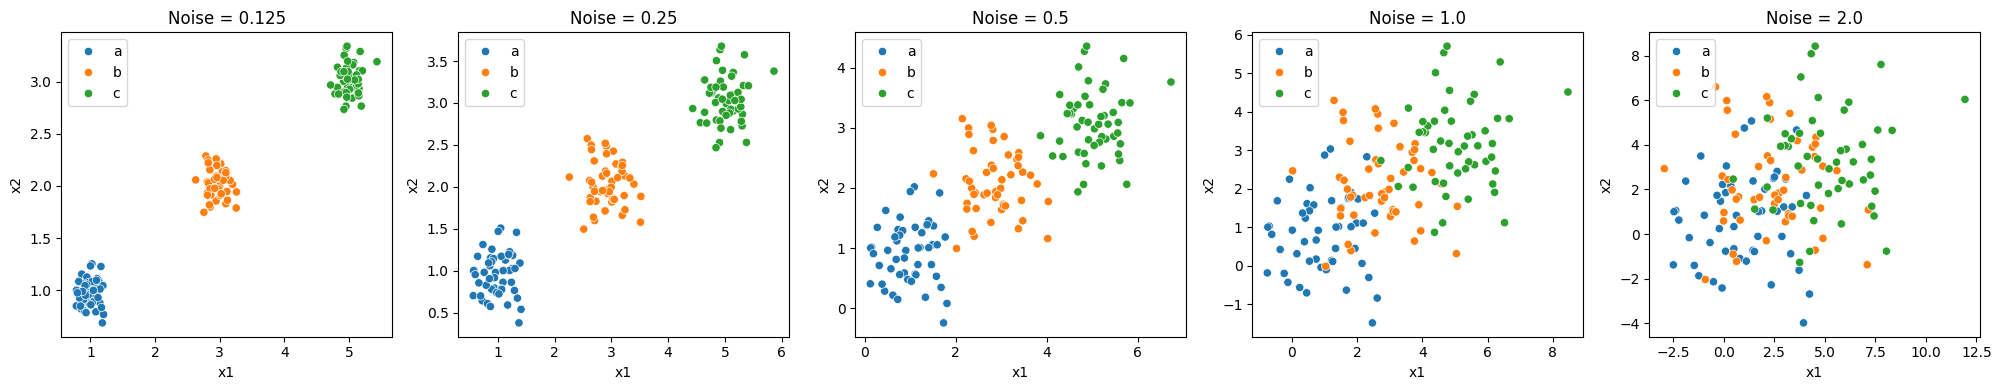

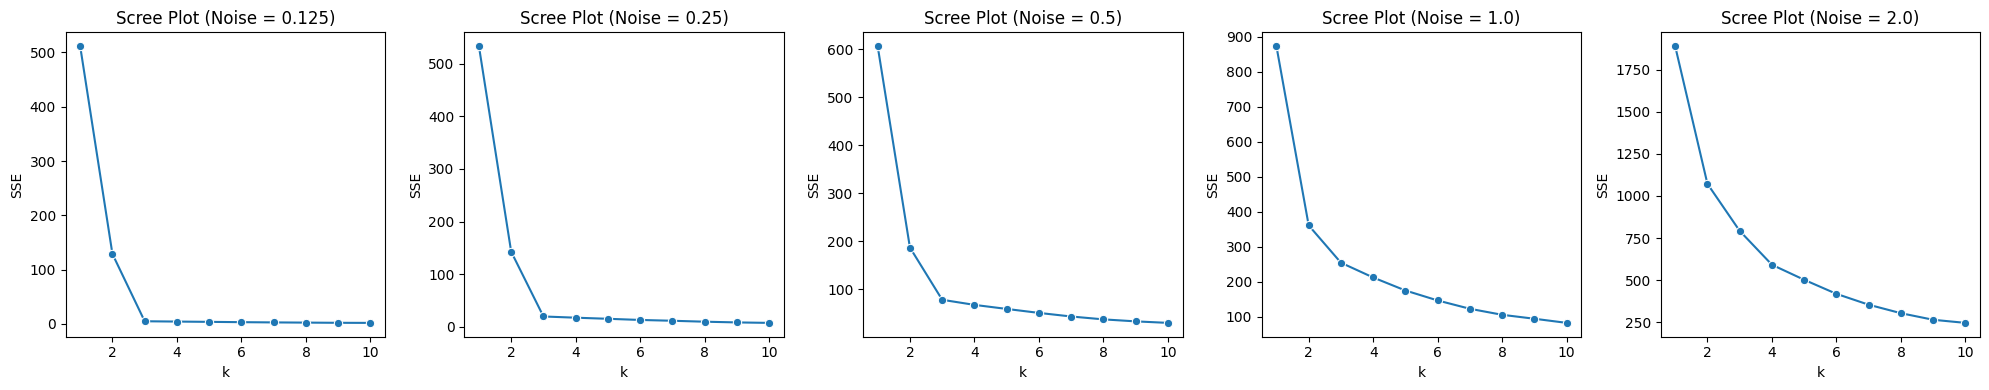

In [507]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 1. Define the data generation function
def createData(noise, N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1, x2, g) triples:
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])

    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

# Create datasets for each noise level
datasets = {
    '0.125': createData(0.125),
    '0.25': createData(0.25),
    '0.5': createData(0.5),
    '1.0': createData(1.0),
    '2.0': createData(2.0)
}

# 2. Scatterplots by group for each dataset
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(20, 4))
for i, (noise_label, df) in enumerate(datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=axes[i])
    axes[i].set_title(f"Noise = {noise_label}")
    axes[i].legend(loc="upper left")
plt.tight_layout()
plt.show()

# Written Answer: As noise increases from 0.125 to 2.0, the clusters
# spread out more widely due to higher variance, leading to heavy
# overlapping between groups 'a', 'b', and 'c' rather than moving to the origin.

# 3. Scree plots for each dataset
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(20, 4))
ks = np.arange(1, 11)

for i, (noise_label, df) in enumerate(datasets.items()):
    X = df[['x1', 'x2']]
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x=ks, y=SSE, ax=axes[i], marker='o')
    axes[i].set_title(f"Scree Plot (Noise = {noise_label})")
    axes[i].set_xlabel("k")
    axes[i].set_ylabel("SSE")

plt.tight_layout()
plt.show()

# Written Answer (Elbow Intuition):
# For low noise (e.g., 0.125), the scree plot features a sharp "elbow" at k=3
# because there are 3 distinct, well-separated natural clusters. As noise increases
# toward 2.0, the points blur into a single continuous cloud, flattening out the
# curve and making the elbow disappear, which makes selecting k definitively impossible.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 8.2+ KB
None
             index    Year  Spending (2020 USD)  Percent of GDP  \
count   148.000000   148.0           148.000000      148.000000   
mean   2831.256757  2020.0         13153.747670        0.019619   
std    1654.299355     0.0         68005.236120        0.015033   
min      32.

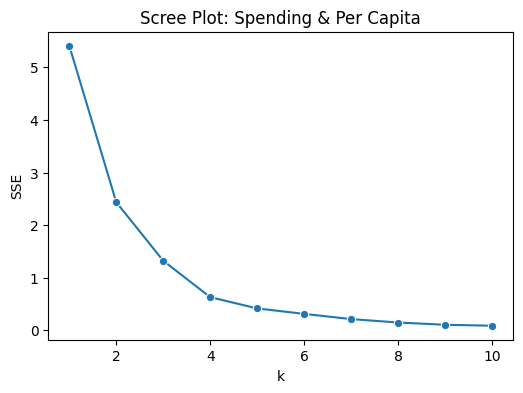

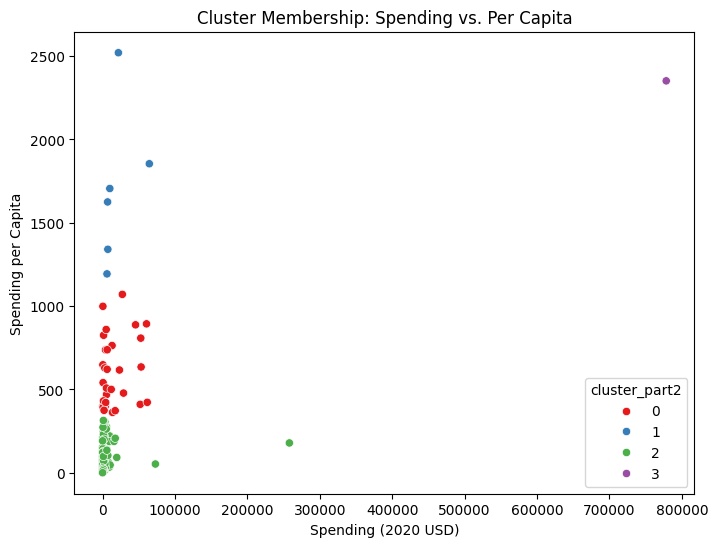

              Spending (2020 USD)                                              \
                            count           mean           std            min   
cluster_part2                                                                   
0                            30.0   17077.591354  20583.053357     405.790494   
1                             6.0   19443.362047  22861.507114    6095.708713   
2                           111.0    4859.185065  25405.739131       8.622460   
3                             1.0  778397.200000           NaN  778397.200000   

                                                                           \
                         25%            50%            75%            max   
cluster_part2                                                               
0                2294.039665    5857.060906   26296.001003   61712.537169   
1                7023.251766    8624.225729   18857.070183   64558.400000   
2                 130.010211     382.464677    

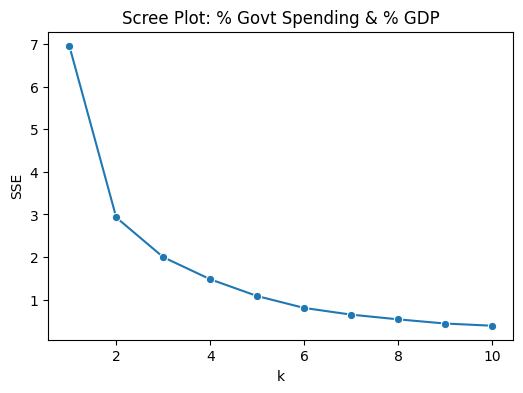

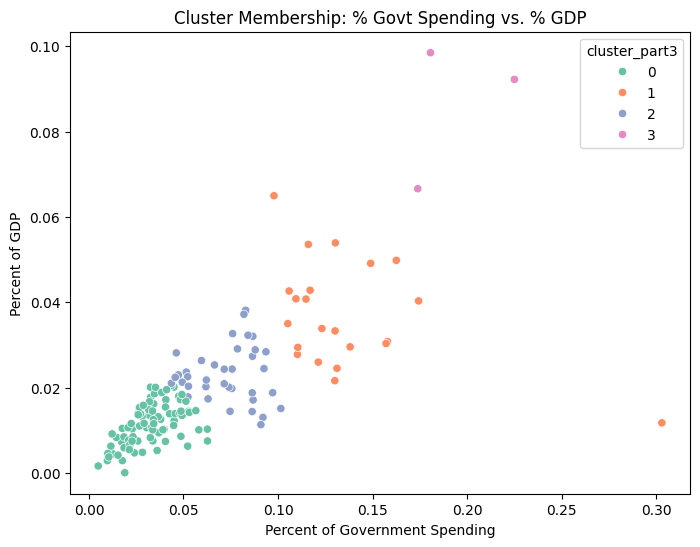

              Percent of Government Spending                                \
                                       count      mean       std       min   
cluster_part3                                                                
0                                       86.0  0.033019  0.013198  0.004896   
1                                       22.0  0.136158  0.042661  0.097882   
2                                       37.0  0.072669  0.016870  0.043592   
3                                        3.0  0.193209  0.027779  0.173924   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
cluster_part3                                                          
0              0.022977  0.032821  0.042267  0.062685           86.0   
1              0.111561  0.126638  0.146304  0.303027           22.0   
2              0.059520  0.075583  0.086497  0.101501           37.0   
3              0.1772

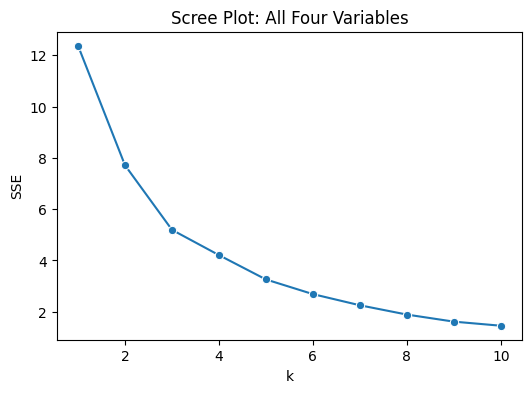

              Spending (2020 USD)                                             \
                            count           mean            std          min   
cluster_part4                                                                  
0                            86.0    4513.543790   27841.230783     8.622460   
1                             6.0  147964.582042  309635.189564  6095.708713   
2                            30.0    9073.543709   18135.032885   163.926877   
3                            26.0   15330.618681   18923.469359   405.790494   

                                                                       \
                       25%           50%           75%            max   
cluster_part4                                                           
0                81.022976    288.061512   1138.618231  257973.429834   
1              7700.424616  15897.570598  53872.942442  778397.200000   
2               522.737081   1663.090134   8646.648849   72937.064048   
3

In [508]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 1. Load and Clean Data
# Adjust path as needed depending on your environment
df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')

# Filter for the year 2020 and drop missing values
df = df[df['Year'] == 2020].dropna().reset_index(drop=True)

# Inspect cleaned data structure
print(df.info())
print(df.describe())

# 2. Max-Min Normalize Spending & Spending per Capita
df['Spending_Norm'] = (df['Spending (2020 USD)'] - df['Spending (2020 USD)'].min()) / \
                      (df['Spending (2020 USD)'].max() - df['Spending (2020 USD)'].min())
df['PerCapita_Norm'] = (df['Spending per Capita'] - df['Spending per Capita'].min()) / \
                       (df['Spending per Capita'].max() - df['Spending per Capita'].min())

# Scree Plot for Spending & Per Capita
X_part2 = df[['Spending_Norm', 'PerCapita_Norm']]
ks = np.arange(1, 11)
sse_2 = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_part2).inertia_ for k in ks]

plt.figure(figsize=(6, 4))
sns.lineplot(x=ks, y=sse_2, marker='o')
plt.title("Scree Plot: Spending & Per Capita")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

# K-Means Clustering (k=4 based on standard heuristic/elbow inspection)
kmeans_2 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_part2)
df['cluster_part2'] = kmeans_2.labels_

# Scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_part2', palette='Set1')
plt.title("Cluster Membership: Spending vs. Per Capita")
plt.show()

# Conditional Describe Table
print(df.groupby('cluster_part2')[['Spending (2020 USD)', 'Spending per Capita']].describe())


# 3. Max-Min Normalize Percent of Government Spending & Percent of GDP
df['Gov_Norm'] = (df['Percent of Government Spending'] - df['Percent of Government Spending'].min()) / \
                 (df['Percent of Government Spending'].max() - df['Percent of Government Spending'].min())
df['GDP_Norm'] = (df['Percent of GDP'] - df['Percent of GDP'].min()) / \
                 (df['Percent of GDP'].max() - df['Percent of GDP'].min())

X_part3 = df[['Gov_Norm', 'GDP_Norm']]
sse_3 = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_part3).inertia_ for k in ks]

plt.figure(figsize=(6, 4))
sns.lineplot(x=ks, y=sse_3, marker='o')
plt.title("Scree Plot: % Govt Spending & % GDP")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

kmeans_3 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_part3)
df['cluster_part3'] = kmeans_3.labels_

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_part3', palette='Set2')
plt.title("Cluster Membership: % Govt Spending vs. % GDP")
plt.show()

print(df.groupby('cluster_part3')[['Percent of Government Spending', 'Percent of GDP']].describe())


# 4. K-Means Clustering with ALL FOUR Numeric Variables (Fully Normalized)
X_part4 = df[['Spending_Norm', 'PerCapita_Norm', 'Gov_Norm', 'GDP_Norm']]

sse_4 = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_part4).inertia_ for k in ks]

plt.figure(figsize=(6, 4))
sns.lineplot(x=ks, y=sse_4, marker='o')
plt.title("Scree Plot: All Four Variables")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

kmeans_4 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_part4)
df['cluster_part4'] = kmeans_4.labels_

print(df.groupby('cluster_part4')[['Spending (2020 USD)', 'Spending per Capita',
                                   'Percent of Government Spending', 'Percent of GDP']].describe())

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements that I found using Google Gemini were the technical, safer, and standard or formal way of solving these problems. For problem one, which asks compare different SSE graphs, growths, scree plots, and scatter plots. For most of them, it provided a more formal approach to them, such as including the formal words for the equations and code. The suggestions that the AI provided were to make it more optimal and formal rather than making it correct because my responses were mostly correct. For problem two, the code that it modified and improved the ways that I used some functions inlucing including fixing a bug to make code safer. Overall, the AI was accurate and provided me with effective criticism for the equation and my code to make them for technically and formally accurate.